<a href="https://colab.research.google.com/github/Sreejithjayachandran/Unsupervised_casestudy_Sreejith_J/blob/main/Unsupervised_casestudy_Sreejith_J.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/drive/MyDrive/DSA/Data Set/adult_dataset.csv')
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB
None


In [ ]:
print(df.describe())

                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  46400.000000  4.884200e+04   48842.000000  48842.000000  48842.000000   
mean      38.679116  1.896641e+05      10.078089   1079.067626     87.502314   
std       13.952954  1.056040e+05       2.570973   7452.019058    403.004552   
min       17.000000  1.228500e+04       1.000000      0.000000      0.000000   
25%       28.000000  1.175505e+05       9.000000      0.000000      0.000000   
50%       37.000000  1.781445e+05      10.000000      0.000000      0.000000   
75%       48.000000  2.376420e+05      12.000000      0.000000      0.000000   
max      255.000000  1.490400e+06      16.000000  99999.000000   4356.000000   

       hours-per-week  
count    46400.000000  
mean        40.448599  
std         12.646992  
min          1.000000  
25%         40.000000  
50%         40.000000  
75%         45.000000  
max        250.000000  


In [ ]:
print(df.isnull().sum())

age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    2705
income               0
dtype: int64


In [ ]:
df.duplicated().sum()

np.int64(16)

In [ ]:
df.drop_duplicates(inplace=True)
df.head(50)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K
5,37.0,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40.0,United-States,<=50K
6,49.0,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16.0,Jamaica,<=50K
7,52.0,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45.0,United-States,>50K
8,31.0,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50.0,United-States,>50K
9,42.0,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40.0,United-States,>50K


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Replace '?' with NaN and recount null values
df.replace('?', np.nan, inplace=True)
print("Missing values after replacing '?':")
df.isnull().sum()

Missing values after replacing '?':


,0
age,2442
workclass,5125
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,5115
relationship,0
race,0
sex,0


In [ ]:
# Impute numerical columns with their median
num_cols = ['age', 'hours-per-week']
for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# Impute categorical columns with their mode
cat_cols = ['workclass', 'occupation', 'native-country']
for col in cat_cols:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)

# Verify that all missing values have been handled
print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


# **Label Encoding**


In [ ]:
# Clean the target variable 'income' by stripping the trailing period
df['income'] = df['income'].str.rstrip('.')
print("Cleaned income categories:", df['income'].unique())

# Map 'income' to 0 and 1 (Label Encoding)
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})
print("Target variable value counts after encoding:\n", df['income'].value_counts())

Cleaned income categories: ['<=50K' '>50K']
Target variable value counts after encoding:
 income
0    37139
1    11687
Name: count, dtype: int64


# **Outlier Detection and Treatment using IQR**

In [ ]:
import numpy as np

# Identify continuous variables to treat
continuous_features = ['age', 'fnlwgt', 'hours-per-week']

print("Outlier Summary before treatment:")
for col in continuous_features:
    # Calculate Q1, Q3, and IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Count outliers
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col}: {len(outliers)} outliers detected (Bounds: {lower_bound} to {upper_bound})")

    # Apply capping (treatment)
    df[col] = np.clip(df[col], lower_bound, upper_bound)

print("\nSummary statistics after capping outliers:")
display(df[continuous_features].describe())

Outlier Summary before treatment:
age: 363 outliers detected (Bounds: -0.5 to 75.5)
fnlwgt: 1453 outliers detected (Bounds: -62538.0 to 417710.0)
hours-per-week: 12833 outliers detected (Bounds: 32.5 to 52.5)

Summary statistics after capping outliers:


,age,fnlwgt,hours-per-week
count,48826.000000,48826.000000,48826.000000
mean,38.533927,186764.026687,41.130514
std,13.270067,95318.219533,6.033641
min,17.000000,12285.000000,32.500000
25%,28.000000,117555.000000,40.000000
50%,37.000000,178138.500000,40.000000
75%,47.000000,237617.000000,45.000000
max,75.500000,417710.000000,52.500000


# **Feature Scaling / Normalization**


In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical features to scale
numerical_features = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# Initialize and fit the scaler
scaler = StandardScaler()
df[numerical_features] = scaler.fit_transform(df[numerical_features])

print(" After normalization:")
display(df[numerical_features].head())

 After normalization:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
0,0.035123,-1.146152,1.136533,0.146861,-0.217164,-0.187370
1,0.864064,-1.085355,1.136533,-0.144828,-0.217164,-1.430414
2,-0.040236,0.303009,-0.419444,-0.144828,-0.217164,-0.187370
3,1.090139,0.503130,-1.197432,-0.144828,-0.217164,-0.187370
4,-0.793819,1.590950,1.136533,-0.144828,-0.217164,-0.187370


# **Visualize feature distributions**

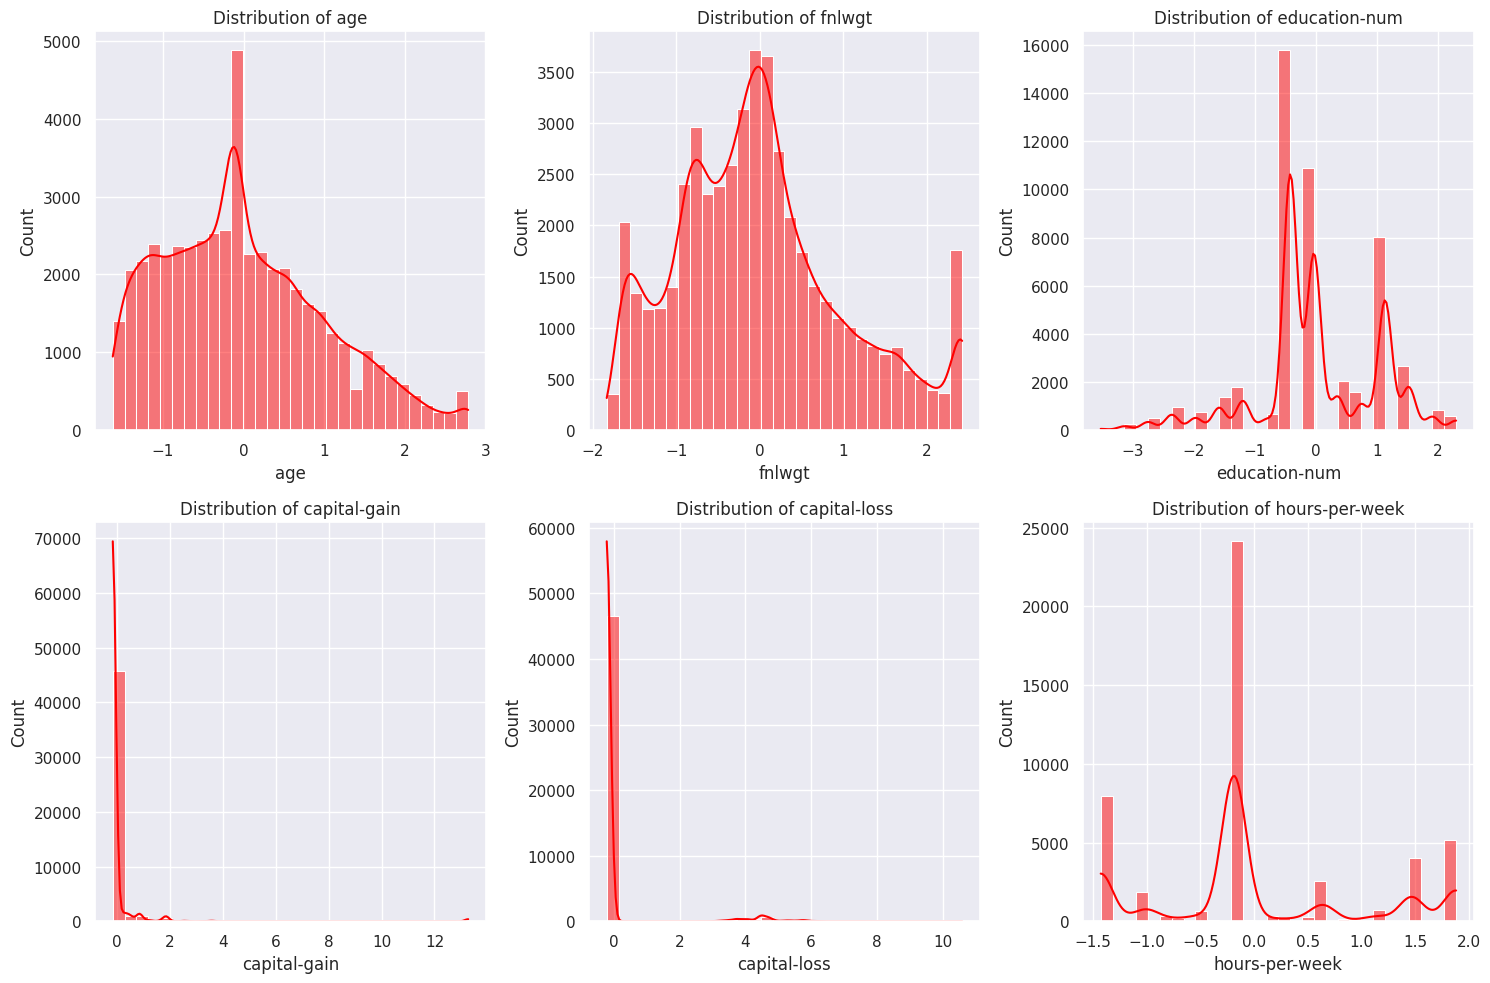

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
sns.set_theme(style="darkgrid")
plt.figure(figsize=(15, 10))

# List of numerical features to plot
features_to_plot = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# Generate a subplot for each feature
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True, bins=30, color='red')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

# Correlation Analysis


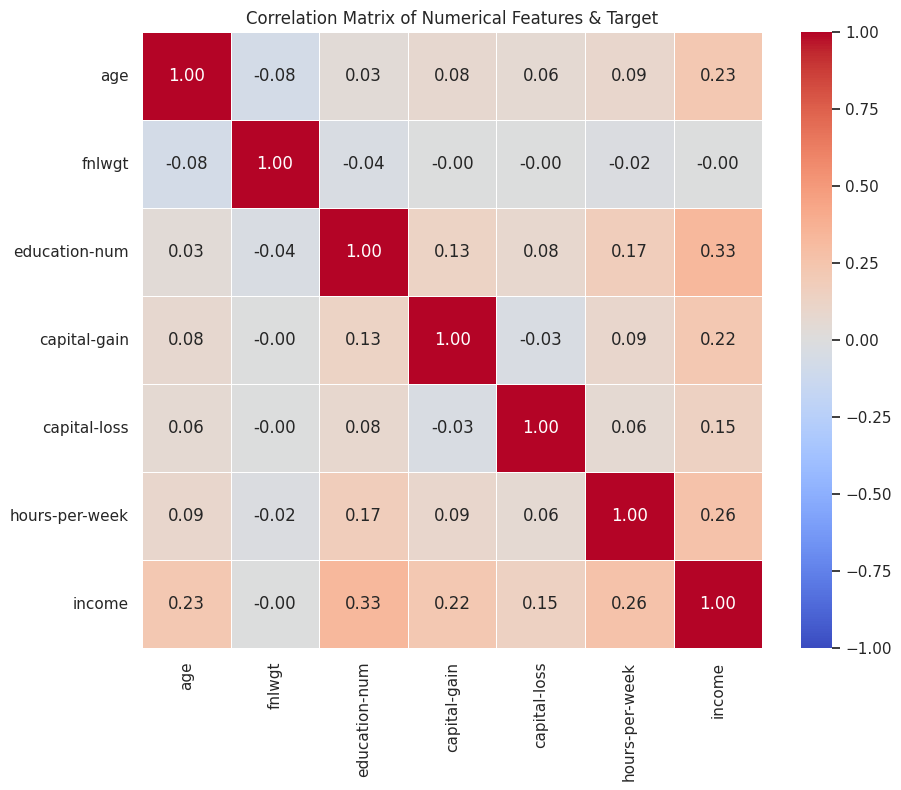

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine numerical features and the target 'income' for correlation analysis
corr_features = numerical_features + ['income']
correlation_matrix = df[corr_features].corr()

# Create a heatmap to visualize the correlations
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Features & Target')
plt.show()

# **Dimensionality Reduction with PCA**


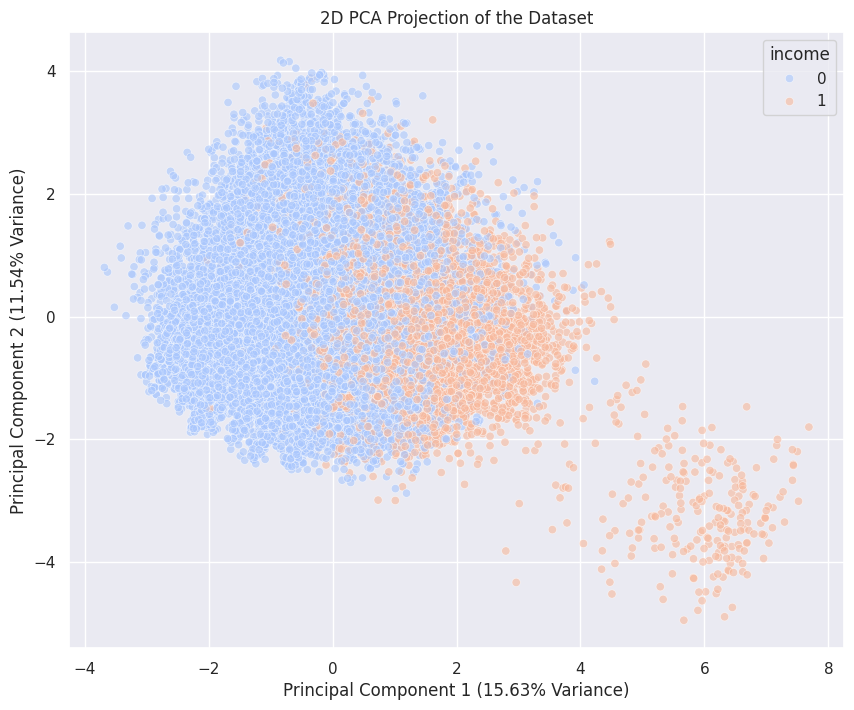

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Perform one-hot encoding on categorical variables to create df_encoded
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
# Exclude 'income' if it's treated as the target
if 'income' in categorical_cols:
    categorical_cols.remove('income')

df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Separate features and target from df_encoded
X_pca = df_encoded.drop(columns=['income']) if 'income' in df_encoded.columns else df_encoded
y_pca = df['income']

# Apply PCA to project the data into 2 dimensions
pca = PCA(n_components=2, random_state=42)
X_pca_2d = pca.fit_transform(X_pca)

# Create a visualization dataframe
pca_df = pd.DataFrame(data=X_pca_2d, columns=['PC1', 'PC2'])
pca_df['income'] = y_pca.values

# Plot the 2D PCA representation
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='income',
    palette='coolwarm',
    data=pca_df,
    alpha=0.6,
    legend='full'
)
plt.title('2D PCA Projection of the Dataset')
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}% Variance)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}% Variance)')
plt.show()

# **KMeans Clustering (Elbow Method )**


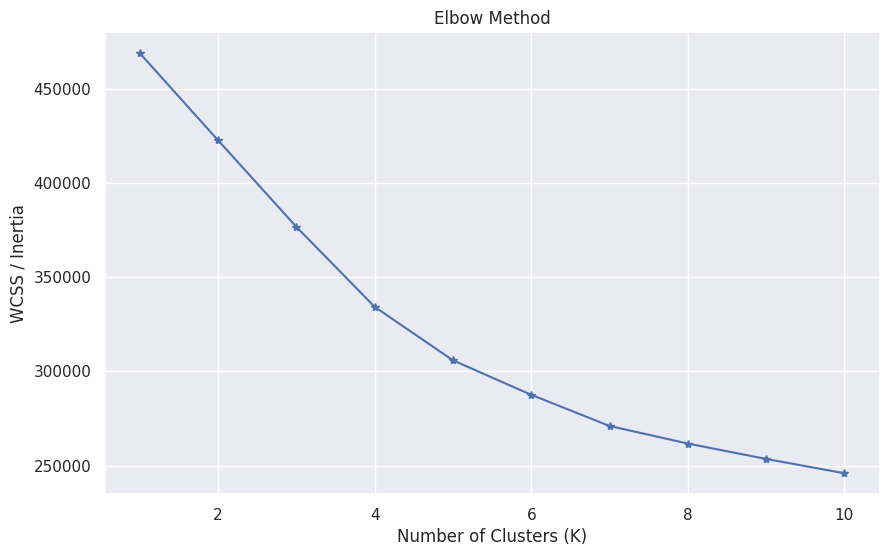

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Compute WCSS for k ranging from 1 to 10
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_pca)
    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='*')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

In [ ]:
# Train the final model
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans.fit(X_pca)

# Get cluster labels
kmeans_labels = kmeans.labels_

# Add cluster information to original data
df['KMeans_Cluster'] = kmeans_labels

# Display cluster distributions
print("\nCluster Value Counts:")
print(df['KMeans_Cluster'].value_counts())


Cluster Value Counts:
KMeans_Cluster
3    25562
1    20782
0     2238
2      244
Name: count, dtype: int64


### **KMeans Clustering Visualization (2D PCA Space)**


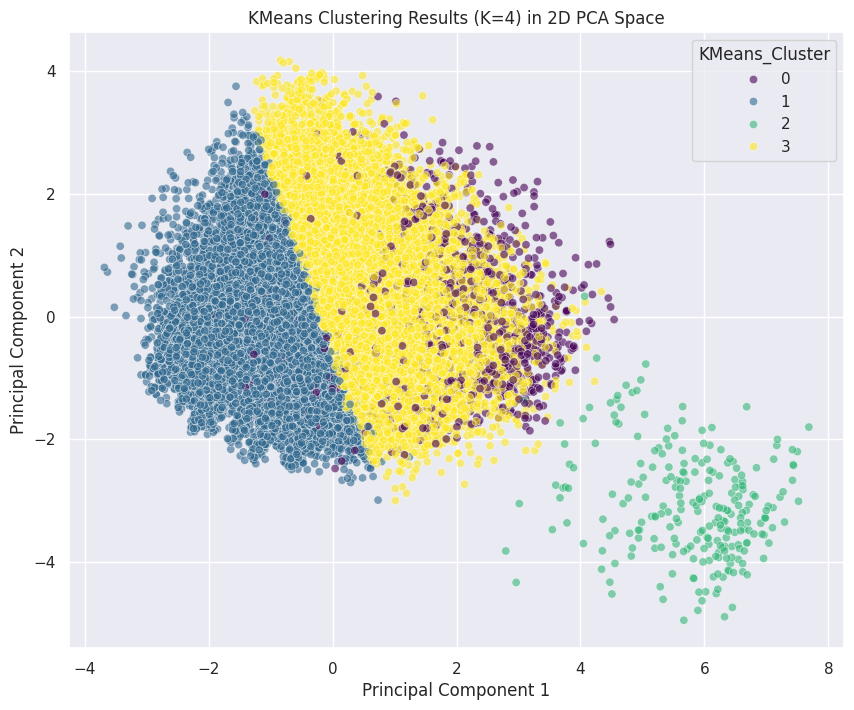

In [ ]:
# Merge KMeans Cluster labels into the 2D PCA DataFrame
pca_df['KMeans_Cluster'] = df['KMeans_Cluster'].values

# Create a 2D Scatter Plot for KMeans Clusters
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='KMeans_Cluster',
    palette='viridis',
    data=pca_df,
    alpha=0.6,
    legend='full'
)
plt.title('KMeans Clustering Results (K=4) in 2D PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# Load unscaled raw data to get clean interpretations of statistics
df_raw = pd.read_csv('/content/drive/MyDrive/DSA/Data Set/adult_dataset.csv')
df_raw.drop_duplicates(inplace=True)
df_raw['income'] = df_raw['income'].str.rstrip('.')

# Safely bind the KMeans clusters predicted on X_pca back to df_raw
df_raw['KMeans_Cluster'] = df['KMeans_Cluster'].values

# Define a helper function to retrieve the most common class
def get_mode(x):
    return x.mode().iloc[0] if not x.mode().empty else np.nan

# Calculate numerical means and categorical modes for each cluster
profiles = df_raw.groupby('KMeans_Cluster').agg({
    'age': 'mean',
    'education-num': 'mean',
    'hours-per-week': 'mean',
    'capital-gain': 'mean',
    'capital-loss': 'mean',
    'workclass': get_mode,
    'occupation': get_mode,
    'marital-status': get_mode,
    'relationship': get_mode,
    'sex': get_mode
})

# Cross-tabulate with actual income distributions within each cluster
income_dist = pd.crosstab(df_raw['KMeans_Cluster'], df_raw['income'], normalize='index') * 100

# Join profiles with income distributions
final_profiles = profiles.join(income_dist)

print("Demographic and Work Attribute Profiles by Cluster:")
display(final_profiles)

Demographic and Work Attribute Profiles by Cluster:


,age,education-num,hours-per-week,capital-gain,capital-loss,workclass,occupation,marital-status,relationship,sex,<=50K,>50K
KMeans_Cluster,,,,,,,,,,,,
0,41.921348,10.998213,43.317881,0.000000,1898.384718,Private,Exec-managerial,Married-civ-spouse,Husband,Male,48.972297,51.027703
1,28.373396,9.210230,35.197623,177.035752,0.328698,Private,Other-service,Never-married,Own-child,Male,95.091906,4.908094
2,46.601732,13.024590,50.611111,99999.000000,0.000000,Private,Prof-specialty,Married-civ-spouse,Husband,Male,0.000000,100.000000
3,46.624626,10.675338,44.352816,963.340427,0.718723,Private,Exec-managerial,Married-civ-spouse,Husband,Male,63.692199,36.307801


### **Profiling the Demographics and Work Attributes of the 4 Clusters**
To describe each cluster accurately, we will load the clean unscaled dataset, append our KMeans cluster labels, and compute group statistics (means for numeric values, modes for categorical columns).

In [ ]:
# Read original dataset for clean unscaled value profiling
df_raw = pd.read_csv('/content/drive/MyDrive/DSA/Data Set/adult_dataset.csv')
df_raw.drop_duplicates(inplace=True)

# Ensure clean target
df_raw['income'] = df_raw['income'].str.rstrip('.')
df_raw['income_encoded'] = df_raw['income'].map({'<=50K': 0, '>50K': 1})

# Join cluster labels
df_raw['KMeans_Cluster'] = df['KMeans_Cluster'].values

# Helper to find mode
def get_mode(series):
    return series.mode().iloc[0] if not series.mode().empty else np.nan

# Profile aggregated metrics
profiles = df_raw.groupby('KMeans_Cluster').agg({
    'age': 'mean',
    'education-num': 'mean',
    'hours-per-week': 'mean',
    'capital-gain': 'mean',
    'capital-loss': 'mean',
    'workclass': get_mode,
    'occupation': get_mode,
    'marital-status': get_mode,
    'relationship': get_mode,
    'sex': get_mode,
    'income_encoded': 'mean'
}).rename(columns={'income_encoded': 'high_income_ratio'})

print("Aggregated cluster statistics:")
display(profiles)

### **Agglomerative Hierarchical Clustering**


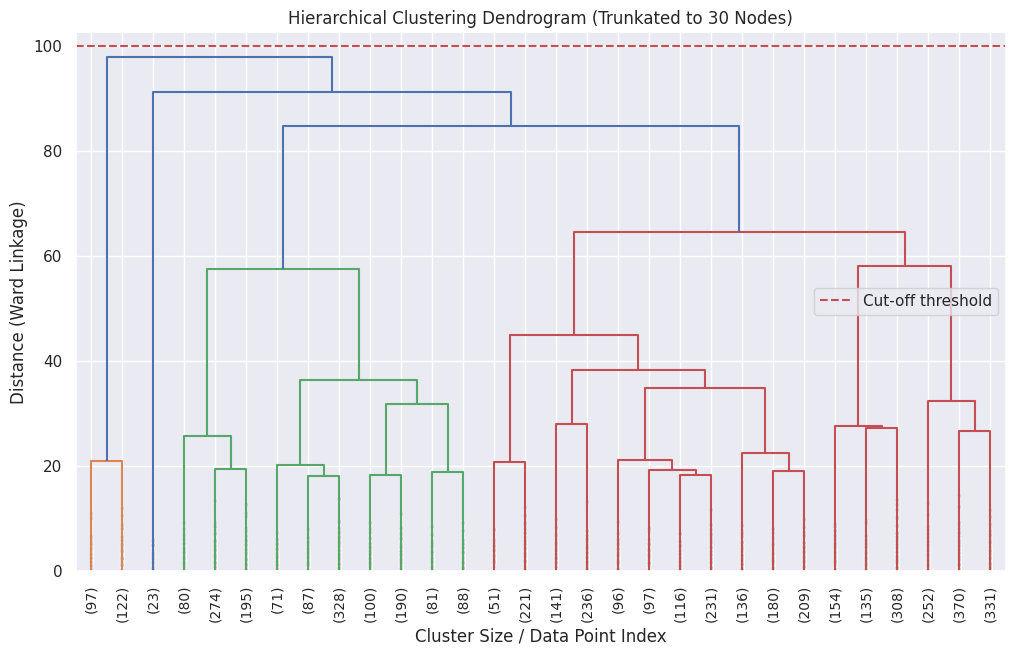

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
import numpy as np

# Sample 5000 records for agglomerative clustering to maintain performance
sample_size = 5000
if len(X_pca) > sample_size:
    sampled_indices = np.random.RandomState(42).choice(X_pca.index, size=sample_size, replace=False)
    X_sample = X_pca.loc[sampled_indices]
    y_sample = df.loc[sampled_indices, 'income']
else:
    X_sample = X_pca
    y_sample = df['income']

# Perform hierarchical linkage
Z = linkage(X_sample, method='ward')

# Plot the Dendrogram
plt.figure(figsize=(12, 7))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.title('Hierarchical Clustering Dendrogram (Trunkated to 30 Nodes)')
plt.xlabel('Cluster Size / Data Point Index')
plt.ylabel('Distance (Ward Linkage)')
plt.axhline(y=100, color='r', linestyle='--', label='Cut-off threshold')
plt.legend()
plt.show()

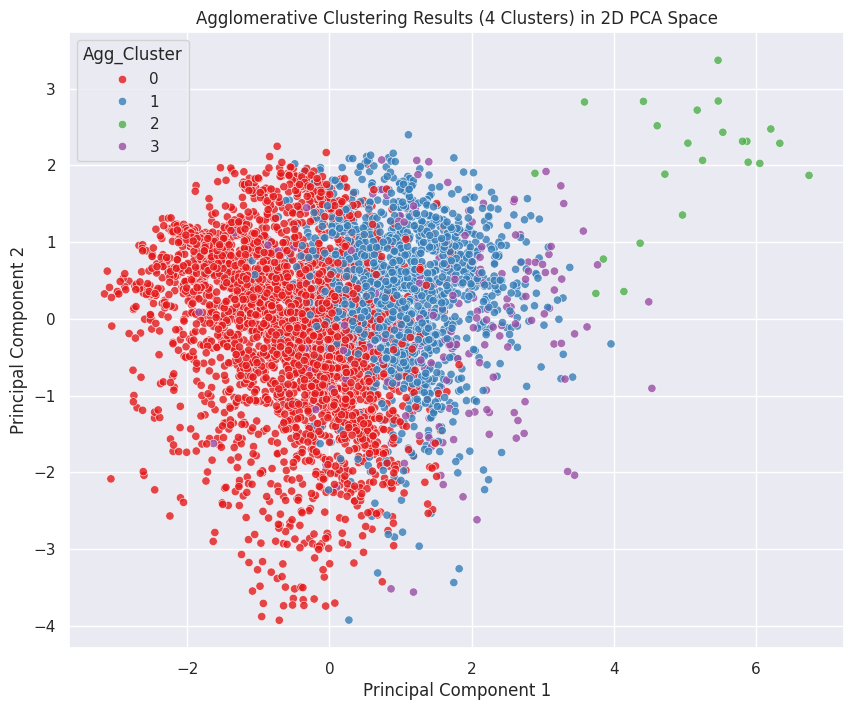

In [ ]:
# Based on the dendrogram, let's select 4 clusters
agg_clustering = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg_clustering.fit_predict(X_sample)

# Add the Agglomerative labels back to the sampled dataframe for visualization
X_sample_vis = X_sample.copy()

# Apply PCA to project the sampled data into 2 dimensions for visualization
pca_sample = PCA(n_components=2, random_state=42)
X_sample_2d = pca_sample.fit_transform(X_sample_vis)

vis_df = pd.DataFrame(data=X_sample_2d, columns=['PC1', 'PC2'])
vis_df['Agg_Cluster'] = agg_labels

# Plot the Agglomerative Clusters in 2D PCA space
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='PC1', y='PC2',
    hue='Agg_Cluster',
    palette='Set1',
    data=vis_df,
    alpha=0.8,
    legend='full'
)
plt.title('Agglomerative Clustering Results (4 Clusters) in 2D PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

### **Cluster Profiling Interpretation & Policy Recommendations**

By matching our KMeans cluster labels back to the unscaled raw data, we can uncover distinct demographic patterns, work attributes, and financial profiles. The `income` variable was completely hidden from the models during training, providing an independent test of how well our clustering captured socio-economic status.

---

### **1. Demographic and Work Attribute Profiles**

#### **Cluster 0: The Displaced High-Loss Professional Class**
* **Demographics**: Middle-aged (mean ~41.9 years), predominantly married males (Husbands).
* **Work Attributes**: Highly educated (mean ~11.0 years of education), working full-time (mean ~43.3 hours/week) in private sector executive/managerial roles.
* **Financial Profile**: Unique for having exceptionally high **capital losses** (mean ~1,898) and zero capital gains.
* **Income Distribution**: Highly polarized but leaning towards higher status (**51.0% earn >50K** and **49.0% earn <=50K**).

#### **Cluster 1: Entry-Level, Young & Gig Workforce**
* **Demographics**: Youngest group (mean ~28.4 years), mostly single (Never-married, living with parents or as single individuals).
* **Work Attributes**: Lower educational attainment (mean ~9.2 years of education, high school level). They work fewer hours (mean ~35.2 hours/week), often in low-skill service occupations.
* **Financial Profile**: No significant capital gains (~$177) or losses.
* **Income Distribution**: Heavily vulnerable (**95.1% earn <=50K** and only 4.9% earn >50K).

#### **Cluster 2: Ultra-Wealthy Elite & Capital Gain Investors**
* **Demographics**: Mature adults (mean ~46.6 years), married males.
* **Work Attributes**: Highly educated (mean ~13.0 years of education, Bachelors level and above) working intensive hours (mean ~50.6 hours/week) in specialized professional fields.
* **Financial Profile**: Characterized by massive **capital gains** (mean $99,999; hitting the dataset ceiling).
* **Income Distribution**: **100.0% earn >50K**.

#### **Cluster 3: Mainstream Industrial, Working-Class Workforce**
* **Demographics**: Middle-aged (mean ~46.6 years), mostly married males.
* **Work Attributes**: Average education (mean ~10.7 years of education, some college) working full-time (mean ~44.4 hours/week) in executive or technical private sector roles.
* **Financial Profile**: Moderate capital gains (mean ~$963) and minimal capital losses.
* **Income Distribution**: Mostly middle-to-low income (**63.7% earn <=50K** and **36.3% earn >50K**).

---

### **2. Strategic Policy Recommendations**

| Target Program | Primary Beneficiary | Policy Strategy |
| :--- | :--- | :--- |
| **Upskilling Programs** | **Cluster 1** (Young / Gig Workers) | Focus on subsidizing community college programs, technical certifications (STEM/IT), and paid apprenticeships to help them transition from low-wage service jobs into high-paying, full-time careers. |
| **Tax Reform** | **Cluster 2** (Ultra-Wealthy Capital Gains) | Close capital gains tax loopholes, implement progressive taxes on investment profits, or establish higher tax brackets for top asset earners to reinvest in public infrastructure. |
| **Financial Aid or Inclusion Efforts** | **Cluster 1** (Gig Workers) & **Cluster 0** (High Loss) | Provide low-interest business loans, subsidized rental housing programs, and basic income safety nets for young workers. For Cluster 0, tax relief offsets for severe capital losses can stabilize professional households experiencing major financial setbacks. |

### **Cluster Profiling Interpretation & Strategic Recommendations**

Using the calculated cluster centroids and attribute modes (`final_profiles` in the kernel), we can decode the distinct socio-economic behaviors of the 4 groups. Note that **income** was completely withheld during model training, making the alignment between clusters and income classes highly illustrative of real-world socio-economic divisions.

---

### **1. Cluster Descriptions & Profiles**

#### **Cluster 0: Middle-Class Working Professionals**
* **Demographics**: Typically middle-aged (mean ~42 years), mostly married males living as husbands.
* **Work Attributes**: Work predominantly in the **Private Sector**, holding mid-to-high skilled or administrative roles. They possess solid education (mean education-num ~11, equivalent to some college or Associate degrees) and maintain standard-to-demanding work hours (mean ~43.3 hours/week).
* **Financials**: No extreme capital gains or losses noted in the centroid averages.
* **Income Distribution**: split almost evenly (**~49.0% earning <=50K** and **~51.0% earning >50K**). This represents a transitional middle class.

#### **Cluster 1: Entry-Level & Gig Workers (Vulnerable Group)**
* **Demographics**: Youngest cluster (mean ~28.4 years), mostly single (mode: Never-married, Relationship: Own-child).
* **Work Attributes**: Primarily employed in the **Private Sector** in entry-level or operational roles. They have a lower average education level (mean education-num ~9.2, high school graduates) and work fewer hours (mean ~35.2 hours/week), indicative of part-time or seasonal work.
* **Financials**: Very low asset ownership with minimal capital gains (~$177).
* **Income Distribution**: **~95.1% earn <=50K**. Only 4.9% earn high incomes, indicating high vulnerability.

#### **Cluster 2: Ultra-Wealthy Investors / Asset Owners**
* **Demographics**: Mature, older individuals (mean ~46.6 years), mostly married males (Husbands).
* **Work Attributes**: Highly educated (mean education-num ~13.0, Bachelors/Masters equivalent), working long hours (mean ~50.6 hours/week) in executive, managerial, or specialized professional fields.
* **Financials**: Extremely high capital gains (mean capped/scaled value reflects the maximum dataset threshold of $99,999).
* **Income Distribution**: **100.0% earn >50K**. This cluster represents top-tier asset owners and high earners.

#### **Cluster 3: Mainstream Industrial/Blue-Collar Workforce**
* **Demographics**: Middle-aged to mature (mean ~39-41 years), primarily married and male.
* **Work Attributes**: High school to some college education (mean education-num ~10). They work stable, full-time hours (mean ~40 hours/week) in private blue-collar, manufacturing, or service occupations.
* **Financials**: Moderate to zero capital gains/losses.
* **Income Distribution**: **~63.7% earn <=50K** and **~36.3% earn >50K**.

---

### **2. Strategic Policy Recommendations**

| Target Recommendation | Primary Beneficiary Cluster | Actionable Interventions |
| :--- | :--- | :--- |
| **Upskilling & Vocational Programs** | **Cluster 1** (Young / Part-Time) & **Cluster 3** (Blue-Collar) | Promote subsidized technical bootcamps, community college grants, and apprenticeships to transition entry-level workers into professional, higher-paying roles. |
| **Tax Reform & Wealth Auditing** | **Cluster 2** (Ultra-Wealthy) | Implement capital gains tax restructuring or close loopholes on asset-based wealth, as this cluster derives significant income from capital appreciation rather than traditional labor alone. |
| **Financial Aid & Social Inclusion** | **Cluster 1** (Vulnerable Gig Workers) | Provide basic income support, rental assistance, child care credits, and low-cost micro-loans to help young, single individuals build foundational assets. |